### Getting_Started 

This notebook gives an explainer of the functionalities of the repository, how to call different functions and parameters that can be changed.

In [1]:
import jax.numpy as jnp
import WDM
import numpy as np
import matplotlib.pyplot as plt

from WDM_LISAresponse.code.lisa_response.response import one_arm_response_td, one_arm_response_wdm_dT
from WDM_LISAresponse.code.utils.utils import wdm_mismatch, compute_wdm_cut_info
from WDM_LISAresponse.code.lisa_response.waveforms import generate_windowed_padded_waveform
from WDM_LISAresponse.code.lisa_response.TDI import gen2_michelson_td, gen2_michelson_wdm
import time
from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits
from few.waveform import GenerateEMRIWaveform
from few.utils.constants import YRSID_SI

Setup of the lisaorbits functions and the EMRI waveform generation functions

In [2]:
td_gen = GenerateEMRIWaveform(
    "FastKerrEccentricEquatorialFlux",
    sum_kwargs=dict(pad_output=True, odd_len=True),
    return_list=True
)

orbit_data = read_orbit_file('esa-trailing-orbits.h5')

orbit_times = orbit_data.t0 + orbit_data.dt * np.arange(orbit_data.size)
t_start = orbit_data.t0

orbits_trailing = InterpolatedOrbits(orbit_times, 
                                     orbit_data.positions, 
                                     orbit_data.velocities)

Parameters for the waveform generation

In [3]:
alpha = 0.01
tukey_factor = 4
t0 = t_start + 1.0*YRSID_SI
N = 10000
dt = 10
Nf = 100

m1 = 1e6
m2 = 10.0
a = 0.9
p0 = 8.5
e0 = 0.3
x0 = 1.0

dist = 1.0
theta = np.pi / 2
phi = 0
qK = np.pi / 3
phiK = np.pi / 3
eps = 1e-2

# initial phases
Phi_phi0 = np.pi / 3
Phi_theta0 = 0.0
Phi_r0 = np.pi / 3

Parameters for WDM operation + additional arguments for the response/TDI functions

In [4]:
q_wdm = 4
L_trunc_value = 25
num_int_points = 100

# Interpolated Tl/Tp can become non-finite for some delay tracks; exact mode is robust.
variable_shift_kwargs = {
        "tl_tp_mode": "interp",
        "tl_tp_interp_kind": "linear",
        "tl_tp_interp_points": 4,
        "tl_tp_interp_pad": 0.0,
        "use_jax": True,
    }

# Optional caches to speed up repeated evaluations in this notebook
one_arm_cache = {}
tdi_shift_cache = {}

Waveform generation + plotting 

Generated padded waveform length: 10400
WDM Nt x Nf = 104 x 100
Tail right padding: 0


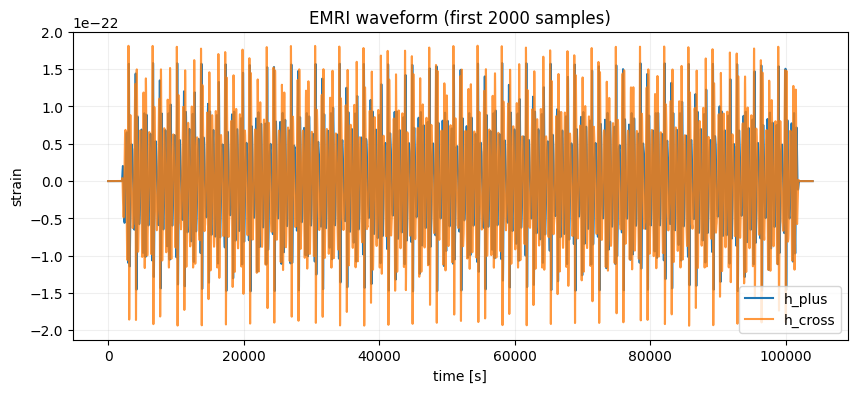

In [5]:
model_kwargs = {
    "td_gen": td_gen,
    "m1": m1,
    "m2": m2,
    "a": a,
    "p0": p0,
    "e0": e0,
    "x0": x0,
    "dist": dist,
    "theta": theta,
    "phi": phi,
    "qK": qK,
    "phiK": phiK,
    "Phi_phi0": Phi_phi0,
    "Phi_theta0": Phi_theta0,
    "Phi_r0": Phi_r0,
    "eps": eps,
}

window_kwargs = {
    "alpha": alpha,
    "tukey_factor": tukey_factor,
}

times_pad, hplus_td, hcross_td, pad_info = generate_windowed_padded_waveform(
    waveform_model="emri",
    t0=t0,
    dt=dt,
    N=N,
    model_kwargs=model_kwargs,
    window_function="tukey",
    window_kwargs=window_kwargs,
    wdm_Nf=Nf,
    return_padding_info=True,
 )

print(f"Generated padded waveform length: {len(times_pad)}")
print(f"WDM Nt x Nf = {pad_info['wdm_Nt']} x {Nf}")
print(f"Tail right padding: {pad_info['wdm_tail_pad_right']}")

plotting_times = times_pad - times_pad[0]

plt.figure(figsize=(10, 4))
plt.plot(plotting_times, hplus_td, label="h_plus")
plt.plot(plotting_times, hcross_td, label="h_cross", alpha=0.8)
plt.title("EMRI waveform (first 2000 samples)")
plt.xlabel("time [s]")
plt.ylabel("strain")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

One-arm response calculation 

In [6]:
t_td0 = time.time()
dl_12_td = one_arm_response_td(
    times_pad,
    1,
    2,
    orbits_trailing,
    theta,
    phi,
    hplus_td,
    hcross_td,
    num_int_points=num_int_points,
 )
t_td1 = time.time()

print(f"TD one-arm runtime: {t_td1 - t_td0:.2f} s")
print(f"TD one-arm shape: {dl_12_td.shape}")

TD one-arm runtime: 0.59 s
TD one-arm shape: (10400,)


In [7]:
t_wdm0 = time.time()
dl_12_wdm_td, _ = one_arm_response_wdm_dT(
    times_pad,
    1,
    2,
    orbits_trailing,
    theta,
    phi,
    hplus_td,
    hcross_td,
    Nf=Nf,
    return_td=True,
    gnm_method="lagrange8",
    d=4,
    q=q_wdm,
    L_trunc=L_trunc_value,
    variable_shift_kwargs=variable_shift_kwargs,
 )
t_wdm1 = time.time()

t_wdm2 = time.time()
w_12_wdm = one_arm_response_wdm_dT(
    times_pad,
    1,
    2,
    orbits_trailing,
    theta,
    phi,
    hplus_td,
    hcross_td,
    Nf=Nf,
    return_td=False,
    d=4,
    q=q_wdm,
    L_trunc=L_trunc_value,
    variable_shift_kwargs=variable_shift_kwargs,
 )
t_wdm3 = time.time()

print(f"WDM one-arm runtime TD: {t_wdm1 - t_wdm0:.2f} s")
print(f"WDM one-arm runtime WDM: {t_wdm3 - t_wdm2:.2f} s")
print(f"WDM one-arm TD projection shape: {dl_12_wdm_td.shape}")
print(f"WDM one-arm coefficient shape: {w_12_wdm.shape}")

WDM one-arm runtime TD: 23.32 s
WDM one-arm runtime WDM: 0.51 s
WDM one-arm TD projection shape: (10400,)
WDM one-arm coefficient shape: (104, 100)


TDI calculation - Michelson

In [8]:
t_tdi_td0 = time.time()
X_td, Y_td, Z_td = gen2_michelson_td(
    times_pad,
    hplus_td,
    hcross_td,
    theta,
    phi,
    orbits_trailing,
    order=7,
 )
t_tdi_td1 = time.time()

print(f"TD TDI runtime: {t_tdi_td1 - t_tdi_td0:.2f} s")
print(f"TD X/Y/Z shapes: {X_td.shape}, {Y_td.shape}, {Z_td.shape}")

TD TDI runtime: 7.70 s
TD X/Y/Z shapes: (10400,), (10400,), (10400,)


In [9]:
t_tdi_wdm0 = time.time()
X_wdm, Y_wdm, Z_wdm = gen2_michelson_wdm(
    times_pad,
    hplus_td,
    hcross_td,
    theta,
    phi,
    orbits_trailing,
    Nf=Nf,
    shifts_cache=tdi_shift_cache,
    L_trunc=L_trunc_value,
    one_arm_cache=one_arm_cache,
    variable_shift_kwargs=variable_shift_kwargs,
    q=q_wdm,
 )
t_tdi_wdm1 = time.time()

print(f"WDM TDI runtime: {t_tdi_wdm1 - t_tdi_wdm0:.2f} s")
print(f"WDM X/Y/Z coefficient shapes: {X_wdm.shape}, {Y_wdm.shape}, {Z_wdm.shape}")

WDM TDI runtime: 2.38 s
WDM X/Y/Z coefficient shapes: (104, 100), (104, 100), (104, 100)


Comparison of the TD and WDM methods in WDM Space

One-arm WDM-domain overlap=0.999977, mismatch=2.344e-05


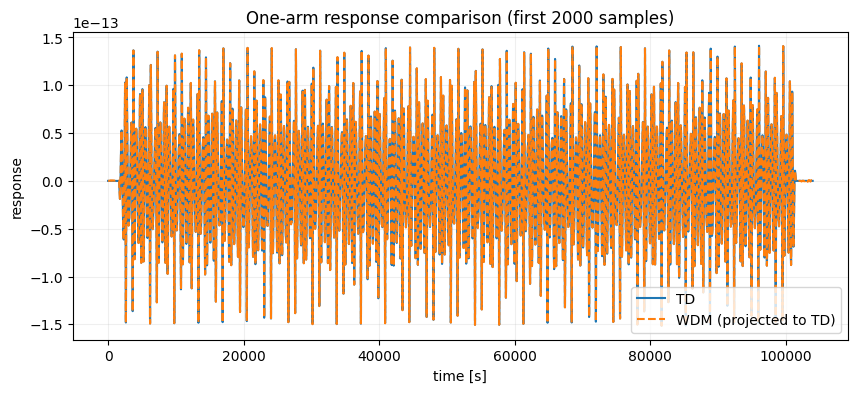

In [10]:
wdm_one_arm = WDM.WDM.WDM_transform(
    dt=dt,
    Nf=Nf,
    N=len(times_pad),
    q=q_wdm,
    d=4,
    calc_m0=True,
 )
w_12_td = wdm_one_arm.dwt(dl_12_td)

cut_info_one_arm = compute_wdm_cut_info(
    original_length=N,
    Nf=Nf,
    dt=dt,
    alpha=alpha,
    tukey_factor=tukey_factor,
    wdm_dT=wdm_one_arm.dT,
    wdm_Nt=wdm_one_arm.Nt,
 )

left_cut = cut_info_one_arm["left_cut"]
right_cut = cut_info_one_arm["right_cut"]

if right_cut > 0:
    td_cut = w_12_td[left_cut:wdm_one_arm.Nt - right_cut, 1:]
    wdm_cut = w_12_wdm[left_cut:wdm_one_arm.Nt - right_cut, 1:].real
else:
    td_cut = w_12_td[left_cut:, 1:]
    wdm_cut = w_12_wdm[left_cut:, 1:].real

ov_wdm, mm_wdm = wdm_mismatch(td_cut, wdm_cut)
print(f"One-arm WDM-domain overlap={ov_wdm:.6f}, mismatch={mm_wdm:.3e}")

plt.figure(figsize=(10, 4))
plt.plot(plotting_times, dl_12_td, label="TD")
plt.plot(plotting_times, dl_12_wdm_td, "--", label="WDM (projected to TD)")
plt.title("One-arm response comparison (first 2000 samples)")
plt.xlabel("time [s]")
plt.ylabel("response")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

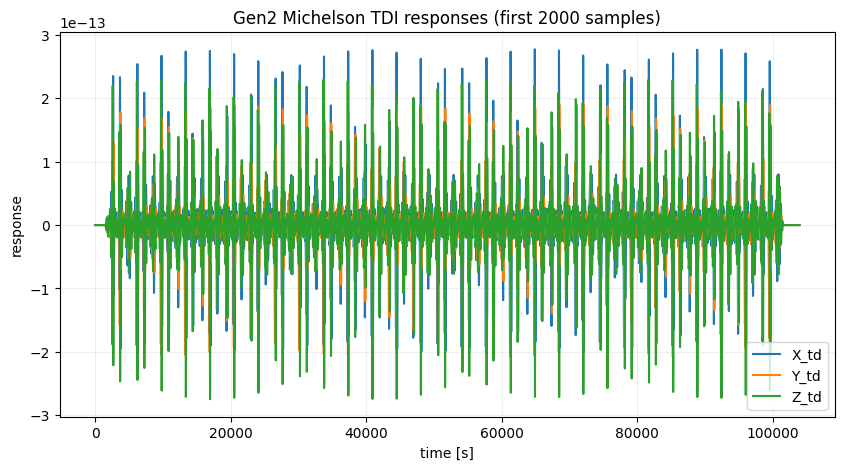

TDI TD-vs-WDM mismatch in WDM domain:
X: overlap=0.999972, mismatch=2.833e-05
Y: overlap=0.999971, mismatch=2.912e-05
Z: overlap=0.999968, mismatch=3.193e-05


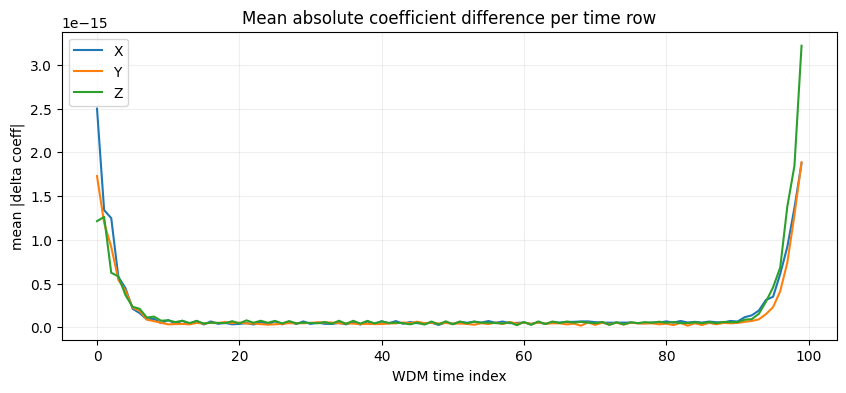

In [11]:
# TDI response plot in the time domain (TD baseline)
plt.figure(figsize=(10, 5))
plt.plot(plotting_times, X_td, label="X_td")
plt.plot(plotting_times, Y_td, label="Y_td")
plt.plot(plotting_times, Z_td, label="Z_td")
plt.title("Gen2 Michelson TDI responses (first 2000 samples)")
plt.xlabel("time [s]")
plt.ylabel("response")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

wdm_tdi = WDM.WDM.WDM_transform(
    dt=dt,
    Nf=Nf,
    N=len(times_pad),
    q=q_wdm,
    d=4,
    calc_m0=True,
 )

X_td_w = wdm_tdi.dwt(X_td)
Y_td_w = wdm_tdi.dwt(Y_td)
Z_td_w = wdm_tdi.dwt(Z_td)

cut_info_tdi = compute_wdm_cut_info(
    original_length=N,
    Nf=Nf,
    dt=dt,
    alpha=alpha,
    tukey_factor=tukey_factor,
    wdm_dT=wdm_tdi.dT,
    wdm_Nt=wdm_tdi.Nt,
 )

lcut = cut_info_tdi["left_cut"]
rcut = cut_info_tdi["right_cut"]

if rcut > 0:
    sl = slice(lcut, wdm_tdi.Nt - rcut)
else:
    sl = slice(lcut, None)

X_ov, X_mm = wdm_mismatch(X_td_w[sl, 1:], X_wdm[sl, 1:].real)
Y_ov, Y_mm = wdm_mismatch(Y_td_w[sl, 1:], Y_wdm[sl, 1:].real)
Z_ov, Z_mm = wdm_mismatch(Z_td_w[sl, 1:], Z_wdm[sl, 1:].real)

print("TDI TD-vs-WDM mismatch in WDM domain:")
print(f"X: overlap={X_ov:.6f}, mismatch={X_mm:.3e}")
print(f"Y: overlap={Y_ov:.6f}, mismatch={Y_mm:.3e}")
print(f"Z: overlap={Z_ov:.6f}, mismatch={Z_mm:.3e}")

plt.figure(figsize=(10, 4))
plt.plot(np.abs(X_td_w[sl, 1:] - X_wdm[sl, 1:].real).mean(axis=1), label="X")
plt.plot(np.abs(Y_td_w[sl, 1:] - Y_wdm[sl, 1:].real).mean(axis=1), label="Y")
plt.plot(np.abs(Z_td_w[sl, 1:] - Z_wdm[sl, 1:].real).mean(axis=1), label="Z")
plt.title("Mean absolute coefficient difference per time row")
plt.xlabel("WDM time index")
plt.ylabel("mean |delta coeff|")
plt.legend()
plt.grid(alpha=0.2)
plt.show()